列表推导式[...]   f-string(格式化字符串)   正态分布，平均值，标准差   二维数组   horizontal stack   

In [31]:
import pandas as pd 
import numpy as np

np.random.seed(42)

genes = [f"Gene_{i}" for i in range(1, 101)]

tumor_data = np.random.normal(loc=100, scale=20, size=(100, 3))
normal_data = np.random.normal(loc=50, scale=15, size=(100, 3))

data_matrix = np.hstack((tumor_data, normal_data))
columns = ['Tumor_1', 'Tumor_2', 'Tumor_3', 'Normal_1', 'Normal_2', 'Normal_3']

df = pd.DataFrame(data_matrix, index=genes, columns=columns)
df


,Tumor_1,Tumor_2,Tumor_3,Normal_1,Normal_2,Normal_3
Gene_1,109.934283,97.234714,112.953771,37.565075,41.597284,61.209404
Gene_2,130.460597,95.316933,95.317261,59.155554,49.686476,51.759911
Gene_3,131.584256,115.348695,90.610512,69.164973,41.126429,58.206461
Gene_4,110.851201,90.731646,90.685405,46.967110,46.734782,66.481653
Gene_5,104.839245,61.734395,65.501643,62.381245,62.202645,69.582182
...,...,...,...,...,...,...
Gene_96,60.958244,96.964298,111.766344,53.723309,43.109587,37.252334
Gene_97,105.619837,87.546010,95.837555,62.455037,37.158743,51.073494
Gene_98,90.139981,88.212705,116.992042,42.835138,57.184697,55.004932
Gene_99,107.140310,86.141808,117.991998,65.563099,42.349754,45.951876


mean均值 axis1横0纵 伪计数+1   差异倍数fold change   T检验，P_values   FDR      利用小括号实现隐式换行、符合 PEP 8 规范的函数参数列表，其中单引号的使用符合PEP 8规范

In [32]:
tumor_mean = df[['Tumor_1', 'Tumor_2', 'Tumor_3']].mean(axis=1)
normal_mean = df[['Normal_1', 'Normal_2', 'Normal_3']].mean(axis=1)

log2fc = np.log2((tumor_mean +1) / (normal_mean +1))

from scipy.stats import ttest_ind
t_stats, p_vals = ttest_ind(
    df[['Tumor_1', 'Tumor_2', 'Tumor_3']],
    df[['Normal_1', 'Normal_2', 'Normal_3']],
    axis=1
)

results = pd.DataFrame({
    'log2FC': log2fc,
    'p_value': p_vals
})

results['-log10(p_value)'] = -np.log10(results['p_value'])

results.head()


,log2FC,p_value,-log10(p_value)
Gene_1,1.172321,0.002378,2.623779
Gene_2,0.986226,0.011375,1.944031
Gene_3,0.989648,0.017502,1.756924
Gene_4,0.855531,0.009336,2.029834
Gene_5,0.253712,0.417657,0.379180


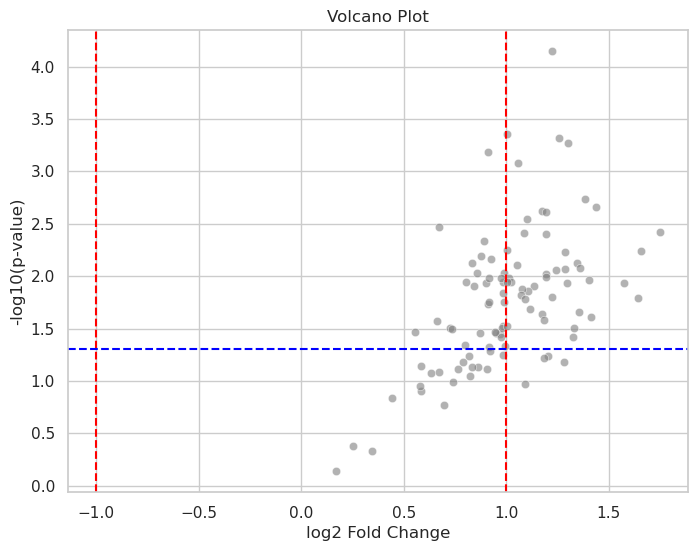

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 6))

sns.scatterplot(data=results, x='log2FC', y='-log10(p_value)', color='gray', alpha=0.6)

plt.axvline(x=1, color='red', linestyle='--')
plt.axvline(x=-1, color='red',linestyle='--')

plt.axhline(y=-np.log10(0.05), color='blue', linestyle='--')

plt.title("Volcano Plot")
plt.xlabel("log2 Fold Change")
plt.ylabel("-log10(p-value)")

plt.show()

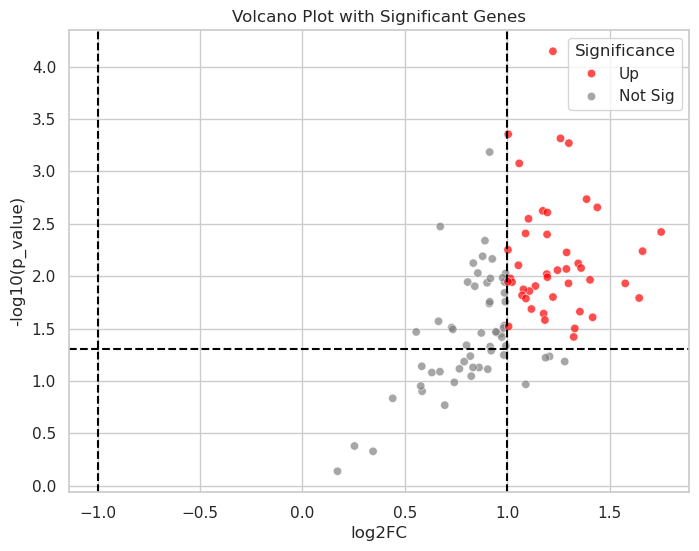

,log2FC,p_value,-log10(p_value),Significance
Gene_1,1.172321,0.002378,2.623779,Up
Gene_2,0.986226,0.011375,1.944031,Not Sig
Gene_3,0.989648,0.017502,1.756924,Not Sig
Gene_4,0.855531,0.009336,2.029834,Not Sig
Gene_5,0.253712,0.417657,0.379180,Not Sig


In [34]:
up = (results['log2FC'] > 1) & (results['p_value'] < 0.05)
down = (results['log2FC'] < -1) & (results['p_value'] < 0.05)

results['Significance'] = 'Not Sig'
results.loc[up, 'Significance'] = 'Up'
results.loc[down, 'Significance'] = 'Down'

plt.figure(figsize=(8, 6))
sns.scatterplot(data=results, x='log2FC', y='-log10(p_value)',
                hue='Significance',
                palette={'Up': 'red', 'Down': 'blue', 'Not Sig': 'grey'},
                alpha=0.7)

plt.axvline(x=1, color='black', linestyle='--')
plt.axvline(x=-1, color='black', linestyle='--')
plt.axhline(y=-np.log10(0.05), color='black', linestyle='--')

plt.title("Volcano Plot with Significant Genes")
plt.show()
results.head()